In [96]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict, Annotated
from langchain_cohere import ChatCohere
from langchain_core.messages import BaseMessage,HumanMessage
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

In [97]:
class state(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [98]:
model_name=	"command-a-03-2025"

In [99]:
model=ChatCohere(model=model_name,temperature=0.5)


In [100]:
def chatNode(state:TypedDict)->dict:
    messages=state['messages']
    result=model.invoke(messages)
    return {
        "messages":[result]
    }

In [101]:
graph= StateGraph(state)
graph.add_node("chatNode",chatNode)
graph.add_edge(START,"chatNode")
graph.add_edge("chatNode",END)
bot=graph.compile(checkpointer=MemorySaver())

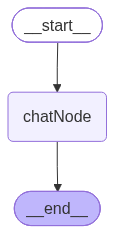

In [102]:
bot

In [103]:
config={
    "configurable":{
        "thread_id":1
    }
}
while True:
    message=input("Type here")
    if message not in ["break","quit","exit"]:
        response=bot.invoke({"messages":[HumanMessage(content=message)]},config=config)
        print(response["messages"][-1].content)
    else:
        break

Hello Dipanshu! It's nice to meet you. How can I assist you today? Whether you have questions, need help with a task, or just want to chat, feel free to let me know!
Your name is **Dipanshu**. How can I assist you further?
It seems there might be a bit of a mix-up, Dipanshu. If you were born in 2025, that would mean you are from the future, which is quite fascinating! However, since we are currently in the year 2023, it’s more likely that you were born before 2025. Could you clarify your birth year? I’d love to help you with any questions or tasks you have!
It seems there might be a bit of confusion. Since you mentioned you were born in 2025, but we are currently in 2023, it's not possible for you to have been born in the future. Could you please clarify your actual birth year? I'd be happy to help you with any questions or tasks you have!
Ah, I see! If it’s the year 2026 and you were born in 2025, that means you are **1 year old** now, Dipanshu! Congratulations on your first year of l

In [104]:
response

{'messages': [HumanMessage(content='my name is dipanshu', additional_kwargs={}, response_metadata={}, id='0d8b3d3f-2fc9-49c9-a01b-f9d9c577b19e'),
  AIMessage(content="Hello Dipanshu! It's nice to meet you. How can I assist you today? Whether you have questions, need help with a task, or just want to chat, feel free to let me know!", additional_kwargs={'id': '9164c778-1fd8-472f-8f8d-591b1f42b251', 'finish_reason': 'COMPLETE', 'token_count': {'input_tokens': 501.0, 'output_tokens': 46.0}}, response_metadata={'id': '9164c778-1fd8-472f-8f8d-591b1f42b251', 'finish_reason': 'COMPLETE', 'token_count': {'input_tokens': 501.0, 'output_tokens': 46.0}}, id='lc_run--01a1868f-d514-769e-a9d9-883677834138-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 501, 'output_tokens': 46, 'total_tokens': 547}),
  HumanMessage(content='what is my name', additional_kwargs={}, response_metadata={}, id='9c03a30d-b84f-44a1-8be1-ba9e761106d2'),
  AIMessage(content='Your name is **Dipanshu**.